# 6장 2강: 전이학습 전략과 성능 비교 — 실습문제

## 실습 목표

- Scratch Training과 Transfer Learning의 출발점 차이를 구분합니다.
- Feature Extraction과 Fine-tuning을 같은 대상 데이터·학습 횟수에서 비교합니다.
- 성능은 검증 손실로, 학습 효율은 업데이트 범위와 실제 측정 시간으로 나누어 읽습니다.
- 사전학습 비용의 포함 여부에 따라 전략 선택이 달라질 수 있음을 설명합니다.

## 구성과 난이도

| 구분 | 문제 | 내용 |
|---|---|---|
| 실습 1 | 1-1 | 비교 조건 확인과 교육용 사전학습 |
| 실습 1 | 1-2 | Scratch·Feature Extraction·Fine-tuning 실행 |
| 실습 2 | 2-1 | 최종 손실과 Learning Curve 비교 |
| 실습 2 | 2-2 | 업데이트 범위·측정 시간·사전학습 비용 비교 |
| 기초 과제 | 3-1 | 성능 조건과 비용 조건에 맞춰 전략 선택 |

**실습 2개 + 기초 과제 1개**입니다. 모델 학습과 시간 측정 함수는 제공하므로 새로 구현할 필요가 없습니다. 정해진 실험을 실행하고 표·그래프를 읽는 기초 수준입니다.

제공된 **6장 2강 목차**를 기준으로 구성했습니다. 강의 본문은 별도로 제공되지 않았으므로 기간·모델 크기·학습 횟수·학습률은 원리를 확인하는 실습용 설정입니다. 최적 성능 탐색이나 대규모 모델 실험은 요구하지 않습니다.

## 데이터와 실행 방법

- `전기사용량(2).csv`, `building_info(2).csv`를 노트북과 같은 폴더에 두세요. 괄호가 없는 `전기사용량.csv`, `building_info.csv`도 읽습니다.
- Python, NumPy, pandas, Matplotlib을 사용합니다. 별도 딥러닝 프레임워크나 GPU는 필요하지 않습니다.
- 전력 기록 204,000행과 건물 정보 100행을 `건물번호`로 연결합니다. 입력은 기온·습도·시간·요일·연면적·냉방면적 6개, 정답은 전력소비량(kWh)입니다.
- 연면적과 냉방면적은 `building_info`에서 가져옵니다. 건물번호는 분리·연결 기준이며 모델의 숫자 입력으로 넣지 않습니다.
- 강수량·일조·일사·설비 용량은 이번 입력에서 제외합니다. 선택한 구간의 사용 열에는 결측값이 없으며 코드로 확인합니다.
- 입력은 해당 시각의 기상 조건입니다. 미래 기상을 모르는 상태에서 다음 날 사용량을 예측하는 실험은 아닙니다.

| 역할 | 건물 | 기간(양 끝 포함) | 행 수 |
|---|---|---|---:|
| Source 사전학습 | 1~4번 | 2022-06-01 00시~06-30 23시 | 2,880 |
| Target 학습 | 5번 | 2022-07-01 00시~07-07 23시 | 168 |
| Target 검증 | 5번 | 2022-07-08 00시~07-14 23시 | 168 |

앞 강의와 같은 건물·기간을 사용합니다. 나머지 자료는 사용하지 않습니다. 사전학습 모델은 이 노트북에서 Source로 직접 만드는 **교육용 작은 신경망**이며 외부 범용 모델은 아닙니다. 검증 정답은 가중치 업데이트에 사용하지 않습니다.

## 이번 강의의 공통 단위 변환

Scratch가 Source의 평균·표준편차도 사용하지 않도록, 이번에는 세 전략 모두 아래의 **고정된 단위 변환**을 사용합니다. 이 기준은 데이터를 보고 추정하는 통계가 아닙니다. 전처리는 제공 코드이며 새로 설계하는 과제가 아닙니다.

| 입력 | 제공 변환 |
|---|---|
| 기온 | (기온−20)/10 |
| 습도 | (습도−50)/20 |
| 시간 | (hour−11.5)/7, hour는 0~23 |
| 요일 | (weekday−3)/2, 월요일 0~일요일 6 |
| 연면적·냉방면적 | 각각 100,000으로 나누기 |
| 정답 | 전력소비량(kWh)/1,000 |

예를 들어 2,000 kWh는 정답 2.0으로 변환됩니다. MSE는 이 **변환된 정답**에서 계산합니다. MSE 1.3은 1.3 kWh 오차나 정확도 130%가 아닙니다. 예측값을 kWh로 되돌리려면 1,000을 곱합니다.

**6장 1강의 Source 평균·표준편차를 사용한 전처리와 다릅니다.** 따라서 그 강의의 손실 숫자나 학습된 가중치를 이 노트북에 그대로 섞어 비교하지 않습니다. 이번 Source 사전학습도 새 변환 기준으로 다시 수행합니다.

## 비교 조건

모델은 모두 **입력 6개 → Tanh 은닉 뉴런 8개 → 출력 1개**입니다. 은닉층 W1·b1은 56개, 출력층 W2·b2는 9개로 전체 65개입니다. 대상 학습의 출력층 초기값은 세 전략에서 동일하게 맞춥니다.

| 전략 | 은닉층의 출발점 | 1~300 epoch | 301~400 epoch |
|---|---|---|---|
| Scratch | 무작위 초기값 | 전체 65개 학습, lr=0.03 | 전체 65개 학습, lr=0.003 |
| Feature extraction | Source 학습값 | 은닉층 고정·출력층 9개 학습, lr=0.03 | 같은 고정 유지, lr=0.003 |
| Fine-tuning | Source 학습값 | 은닉층 고정·출력층 9개 학습, lr=0.03 | 고정 해제·전체 65개 학습, lr=0.003 |

학습률을 바꾸는 코드를 학생이 새로 설계할 필요는 없습니다. 비교를 위한 두 구간의 고정 설정입니다. 세 전략은 같은 대상 학습 168행을 총 400회 사용합니다. Transfer 두 전략은 여기에 **Source 2,880행으로 600 epoch 사전학습한 지식**을 추가로 사용합니다. 대상 학습 횟수가 같다는 것은 전체 데이터·총 계산량까지 같다는 뜻은 아닙니다.

이번 비교는 세 **전략 전체의 결과**를 비교합니다. Scratch는 은닉층을 400회, Fine-tuning은 대상에서 은닉층을 마지막 100회 조정합니다. 결과 차이를 사전학습 유무 한 가지 원인만으로 설명하지 않습니다.

### 이번 강의에서 답하려는 질문

앞 강의에서는 학습한 값을 가져오고, 은닉층을 고정하거나 다시 조정하는 방법을 배웠습니다. 이번에는 **처음부터 배우기와 기존 학습값을 활용하기 중 어떤 전략을 선택할지** 결과를 보고 판단합니다. 먼저 예측 오차가 얼마나 작은지 확인하고, 그다음 필요한 학습 시간과 사전학습 준비 비용을 구분합니다.

예측이 더 정확해도 학습 시간이 더 걸릴 수 있고, 빠르게 학습해도 필요한 예측 성능을 만족하지 못할 수 있습니다. 따라서 ‘가장 좋다’고 말하기 전에 **무엇을 우선하는 상황인가**를 정해야 합니다. 이 자료의 ‘비용’은 직접 측정한 시간에 관한 뜻이며, 전기요금이나 금전 지출을 계산한 것이 아닙니다.

### 처음 보는 용어부터 연결하기

| 용어 | 쉽게 읽는 뜻 | 이번 비교에서의 역할 |
|---|---|---|
| Scratch Training | 스크래치 학습. 기존에 학습한 가중치 없이 처음부터 학습 | 5번 건물의 학습 자료로 은닉층·출력층 학습 |
| Transfer Learning | 전이학습. 관련 데이터에서 먼저 배운 값을 재사용 | Source에서 배운 은닉층으로 Target 학습 시작 |
| Source | 소스. 먼저 학습하는 자료 | 건물 1~4의 6월 자료 |
| Target | 타깃. 새로 적응할 대상 자료 | 건물 5의 7월 자료 |
| 파라미터 | 학습으로 조정하는 가중치·편향 숫자 | 전체 65개 |
| 특징 추출부·Backbone | 입력을 내부 특징 H로 바꾸는 부분 | 은닉층 W1·b1, 56개 |
| 출력층·Head | H를 최종 예측으로 조합하는 부분 | W2·b2, 9개 |
| Feature Extraction | 사전학습 층에서 특징을 만들어 사용하는 방식 | 이번 전략은 은닉층을 고정하고 출력층만 학습 |
| Fine-tuning | 학습된 파라미터를 대상 자료로 추가 조정 | 이번 전략은 마지막 100 epoch에 은닉층도 조정 |
| Epoch | 학습 자료 전체를 한 번 사용한 단위 | 대상 자료는 각 전략에서 400회 사용 |
| 중앙값·Median | 숫자를 작은 순서로 정렬했을 때 가운데 값 | 3번 잰 시간의 대표값 |
| Benchmark | 같은 절차를 반복하여 실행 시간 등을 측정하는 작업 | 이번에는 시간 비교용 반복 실행 |

**Transfer Learning은 상위 개념**이고, 이번에 비교하는 Feature Extraction·Fine-tuning은 사전학습 은닉층을 이용하는 두 전략입니다. Scratch·Transfer·Feature Extraction·Fine-tuning을 서로 무관한 네 종류의 모델로 외우지 않습니다.

### 성능과 효율을 따로 읽기

| 확인할 것 | 읽을 열 | 좋은 방향 | 이것만으로 알 수 없는 것 |
|---|---|---|---|
| 대상 예측 성능 | valid_mse | 작을수록 검증 예측 오차가 작음 | 학습 시간이나 다른 기간의 보장 성능 |
| 업데이트 범위 | updated_first_300, updated_last_100 | 이번에는 크기·구간을 구분하는 정보 | 개수가 적다고 반드시 더 정확하거나 비례해서 빠른 것은 아님 |
| 대상 적응에 걸린 시간 | target_seconds | 짧을수록 대상 학습을 빨리 마침 | 사전학습을 새로 준비하는 시간 |
| 처음 준비할 때의 추정 시간 | estimated_total_seconds | 짧을수록 측정 범위의 총 준비 시간이 작음 | 파일 읽기·여러 설정 탐색 등 실제 업무의 모든 비용 |

### 주제별 학습 위치

| 강의 주제 | 문제 | 확인할 핵심 |
|---|---|---|
| Scratch Training과 Transfer Learning | 실습 1-1 | 은닉층의 시작값, 추가로 사용하는 Source 정보, 같은 비교 조건 |
| Feature Extraction과 Fine-tuning 비교 | 실습 1-2 | 첫 300회와 마지막 100회의 차이, 동결 여부와 실제 변화 |
| 모델 성능 비교 | 실습 2-1 | 같은 검증 자료·400 epoch·손실 단위에서 오차 비교 |
| 학습 효율 비교 | 실습 2-2 | 파라미터 수, 특징 재사용, 시간 중앙값, 사전학습 비용 |
| 조건에 따른 선택 | 기초 과제 3-1 | 성능 조건을 먼저 만족시킨 뒤 상황에 맞는 시간 기준 적용 |

실습 2개와 기초 과제 1개 구성입니다. 과제는 기존 결과 표를 연결하고 조건을 골라 최솟값을 찾는 필수 수준이며, 새로운 신경망 구현이나 최적 설정 탐색을 요구하지 않습니다.


## 공통 준비 코드 — 그대로 실행하세요

첫 셀은 데이터 연결·분리·고정 단위 변환을 수행합니다. 두 번째 셀은 모델과 학습 함수를 준비합니다.

| 함수 | 역할 |
|---|---|
| `pretrain_source()` | Source로 600 epoch 학습하고 모델·기록·걸린 시간 반환 |
| `make_start(strategy, pretrained)` | 전략별 은닉층과 공통 초기 출력층 구성 |
| `run_strategy(strategy, pretrained)` | 대상에서 두 구간 합계 400 epoch 학습 |
| `change_table(before, after)` | 각 파라미터의 최대 절댓값 변화 확인 |
| `benchmark(pretrained, repeats=3)` | 매번 시작값으로 돌아가 Source 및 세 전략을 각각 3회 시간 측정 |

`run_strategy()`의 반환값은 **최종 모델, 400행의 학습·검증 기록, 대상 학습 시간, 300 epoch 시점 모델**입니다. `Scratch`, `Feature extraction`, `Fine-tuning`의 철자를 그대로 사용하세요.

`fit_segment()`의 `freeze=True`는 은닉층 고정입니다. 고정 구간에서는 같은 입력의 은닉 특징 H를 한 번 계산해 저장하고 재사용합니다. `False`면 은닉층이 바뀌므로 매번 H를 다시 계산합니다. 이 구현 차이도 시간에 반영됩니다. Batch Normalization과 Dropout은 사용하지 않습니다.

시간에는 모델 준비·복사, 특징 계산, 학습, 매 epoch 손실 계산과 기록 정리가 포함됩니다. 대상 시간에는 학습·검증 손실 계산이, Source 시간에는 Source 학습 손실 계산이 포함됩니다. 파일 읽기·전처리·표 출력·그래프 그리기는 포함하지 않습니다. 세 대상 전략에는 같은 평가 주기를 적용합니다.

### 모델 안에서 계산하는 것

모델은 `H = tanh(X @ W1 + b1)`, `예측값 = H @ W2 + b2` 순서로 계산합니다. `@`는 입력과 가중치에서 대응 숫자를 곱해 더하는 행렬곱입니다. b는 편향으로 곱셈 결과에 더하는 값이고, Tanh는 은닉층의 가중합을 −1~1 범위의 비선형 값으로 바꿉니다. H는 원래 여섯 입력을 조합해 만든 여덟 개의 내부 특징입니다.

W1은 6×8=48개, b1은 8개이므로 은닉층은 56개입니다. W2는 8×1=8개, b2는 1개이므로 출력층은 9개입니다. 전체 65개는 네 배열 안에 들어 있는 **개별 숫자 수**입니다. 입력 168행마다 다른 파라미터를 만드는 것이 아니라 모든 행이 같은 가중치·편향을 공유합니다.

### 앞 강의의 설정과 헷갈리지 않기

이번 함수의 `freeze=True`는 **동결한다**, `freeze=False`는 **동결하지 않는다**는 뜻입니다. 앞 강의의 `train_backbone=True`가 ‘은닉층을 학습한다’였던 것과 의미 방향이 반대입니다. True·False만 기억하지 말고 변수 이름까지 함께 읽으세요.

고정된 같은 입력 X와 같은 W1·b1이면 H도 같습니다. 그래서 이번 `fit_segment()`는 동결된 구간에서 H를 **한 번 계산해 저장한 뒤 재사용**합니다. 은닉층을 없애거나 H를 0으로 만드는 것이 아닙니다. 입력이나 은닉층 값이 바뀌면 같은 저장값을 계속 사용할 수 없습니다.

### 단위 변환을 실제 숫자로 읽기

기온이 30이면 `(30−20)/10=1`, 습도가 70이면 `(70−50)/20=1`입니다. 이 숫자 20·10·50·20은 데이터를 보고 구한 평균·표준편차가 아니라 제공된 고정 기준입니다. 따라서 이번 변환을 ‘모든 입력의 평균을 0·분산을 1로 맞춘 것’이라고 설명하지 않습니다.

전력소비량은 1,000으로 나누므로 2,000 kWh는 2, 3,000 kWh는 3입니다. 예측 3과 실제 2를 비교하면 오차는 1, 제곱 오차도 1입니다. MSE는 이 제곱 오차들을 모두 더하고 샘플 수로 나눈 평균입니다. 코드의 `**2`는 제곱, `np.mean(...)`은 평균입니다. 표의 MSE는 원래 kWh 오차나 정확도(%)가 아닙니다.

### 시간 표시와 계산 기호

`seconds`는 초(s), 그래프의 `Milliseconds`는 밀리초(ms)입니다. **1초=1,000밀리초**이므로 0.02초는 20ms입니다. 변환은 시간을 더 빠르게 만드는 작업이 아니라 표시 단위를 바꾸는 작업입니다. `perf_counter()`의 끝값에서 시작값을 빼서 해당 함수 실행 중 지난 시간을 구합니다.

3회 시간의 중앙값은 작은 순서대로 놓은 세 값 중 둘째 값입니다. 0.010·0.012·0.030초이면 중앙값은 0.012초이며, 세 값의 합을 3으로 나눈 평균과는 다릅니다. 실제 수치는 실습 출력에 기록됩니다. 출력 소수점 자리가 많다고 측정 환경의 흔들림이 없어지는 것은 아닙니다.

### 결과를 담는 코드 이름

| 이름 | 담기는 내용 |
|---|---|
| models | 각 전략의 400 epoch 종료 가중치·편향 |
| mid_models | 각 전략의 300 epoch 시점 가중치·편향 |
| histories | 각 전략의 epoch별 학습·검증 MSE 기록 |
| performance | 같은 종료 시점의 성능 비교 표 |
| timing_runs | Source와 세 전략의 실제 반복 측정값 |
| efficiency | 측정 중앙값과 업데이트 범위·비용 비교 표 |
| comparison, eligible | 성능·효율을 합친 표, 성능 조건을 통과한 후보 표 |

딕셔너리는 이름과 값을 짝지어 보관하는 구조입니다. 예를 들어 `models['Scratch']`는 Scratch 최종 모델, `histories['Scratch']`는 그 모델의 학습 기록을 찾습니다. `.idxmin()`은 선택한 열이 가장 작은 행의 이름·번호를 반환하고 `.loc[...]`는 그 행을 가져옵니다. 작은 숫자가 무엇인지뿐 아니라 어떤 열을 최소화했는지 확인하세요.

준비 코드 두 셀부터 실습·과제 순으로 실행합니다. 앞 강의의 변수나 모델을 가져오지 않아도 이 노트북 안에서 필요한 사전학습을 수행합니다. 같은 이름의 파일이라도 앞 강의의 전처리·가중치·손실과 이번 결과를 섞지 않습니다.


### 코드가 처음인 학생을 위한 읽기 안내

이번에는 모델을 새로 설계하는 것보다 **같게 맞춘 조건 → 달리한 조건 → 실제 결과 → 상황별 선택**을 연결하는 것이 중요합니다. 제공 함수를 먼저 실행한 뒤, 각 문제의 표·그래프를 근거로 자신의 말로 답하세요. 준비 함수의 미분식을 새로 유도하는 과제는 아닙니다.

| 코드 | 쉬운 뜻 | 이번 실습에서 읽는 방법 |
|---|---|---|
| `이름 = 값` | 오른쪽 결과를 왼쪽 이름에 저장 | models에는 최종 모델, histories에는 학습 기록 |
| `==`, `!=`, `<=` | 같음, 다름, 작거나 같음 비교 | `valid_mse <= 1.60`은 기준 통과 여부 |
| `params["W1"]` | 이름표 W1로 저장된 배열 꺼내기 | 은닉층 가중치 확인 |
| `.shape`, `.size` | 배열의 행·열 모양, 전체 숫자 개수 | W1은 (6,8), 숫자는 48개 |
| `for`, `if` | 반복, 조건에 맞을 때만 실행 | 전략 세 개 반복, 동결하지 않을 때만 은닉층 업데이트 |
| `.copy()` | 독립적인 사본 만들기 | 앞 전략을 바꾸지 않고 다음 전략 실행 |
| `@`, `*`, `**2` | 행렬곱, 곱하기, 제곱 | 가중합·학습률 적용·제곱 오차를 구분 |
| `.iloc[[0,-1]]` | 첫 행과 마지막 행 선택 | 첫 업데이트 후와 마지막 업데이트 후 손실 |
| `.loc[...idxmin()]` | 값이 가장 작은 행 찾기 | 선택할 열과 후보 범위를 함께 확인 |
| `groupby(...).median()` | 같은 이름끼리 묶어 중앙값 계산 | 전략마다 3회 측정값의 가운데 값 |
| `None` | 해당 값이 제공되지 않음 | Source 학습에는 검증 자료를 넘기지 않음 |
| `_` | 반환값을 받지만 이후 쓰지 않는 관례적 이름 | 시간 측정에서는 완료 모델을 보관하지 않음 |

**freeze는 ‘고정한다’는 뜻입니다.** True면 은닉층을 고정하고 False면 조정합니다. 앞 강의의 train_backbone은 ‘은닉층을 학습한다’는 뜻이었으므로 True·False의 의미가 반대입니다. 변수 이름과 값을 함께 읽으세요. `np.array_equal(...)`의 True는 학습 설정이 아니라 ‘두 배열이 같다’는 검사 결과입니다.

노트북은 준비 두 셀→실습 1→실습 2→기초 과제→실습 마무리 순으로 사용합니다. CSV를 찾지 못하면 파일 이름과 실행 폴더를, 변수 오류가 나면 앞 셀의 실행 여부를 확인합니다. 커널을 다시 시작했으면 앞 강의 변수에 의존하지 말고 이 노트북의 처음부터 실행하세요.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_file(names):
    for name in names:
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError("노트북과 같은 폴더에 파일을 넣어 주세요: " + ", ".join(names))


power = pd.read_csv(find_file(["전기사용량(2).csv", "전기사용량.csv"]), encoding="utf-8-sig")
building = pd.read_csv(find_file(["building_info(2).csv", "building_info.csv"]), encoding="utf-8-sig")
power.columns = power.columns.str.strip()
building.columns = building.columns.str.strip()
assert not power.duplicated(["건물번호", "일시"]).any()
assert building["건물번호"].is_unique
data = power.merge(building[["건물번호", "건물유형", "연면적(m2)", "냉방면적(m2)"]],
                   on="건물번호", how="left", validate="many_to_one", indicator=True)
assert data["_merge"].eq("both").all()
data["time"] = pd.to_datetime(data["일시"], format="%Y%m%d %H")
data["hour"] = data["time"].dt.hour
data["weekday"] = data["time"].dt.dayofweek
data = data.sort_values(["건물번호", "time"]).reset_index(drop=True)

source = data[(data["건물번호"].isin([1,2,3,4])) &
              (data["time"] >= "2022-06-01") & (data["time"] < "2022-07-01")].copy()
target_train = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-01") & (data["time"] < "2022-07-08")].copy()
target_valid = data[(data["건물번호"] == 5) &
                    (data["time"] >= "2022-07-08") & (data["time"] < "2022-07-15")].copy()
features = ["기온(C)", "습도(%)", "hour", "weekday", "연면적(m2)", "냉방면적(m2)"]
target = "전력소비량(kWh)"

# 세 전략 모두 같은 고정 단위를 사용합니다. 데이터에서 통계를 학습하지 않습니다.
x_center = np.array([20.0, 50.0, 11.5, 3.0, 0.0, 0.0])
x_scale = np.array([10.0, 20.0, 7.0, 2.0, 100000.0, 100000.0])
y_scale = 1000.0


def transform(frame):
    X = (frame[features].to_numpy(dtype=float) - x_center) / x_scale
    y = frame[[target]].to_numpy(dtype=float) / y_scale
    return X, y


X_source, y_source = transform(source)
X_train, y_train = transform(target_train)
X_valid, y_valid = transform(target_valid)
for array in [X_source, y_source, X_train, y_train, X_valid, y_valid]:
    assert np.isfinite(array).all(), "선택 구간의 결측값과 숫자 형식을 확인하세요."
print("전력 / 건물 원본 크기:", power.shape, building.shape)
print("연결 후 행 수:", len(data))
print("Source / Target Train / Target Validation:", len(source), len(target_train), len(target_valid))
print("입력 열 순서:", features)
print("정답 변환: 전력소비량(kWh) / 1000")


전력 / 건물 원본 크기: (204000, 10) (100, 7)
연결 후 행 수: 204000
Source / Target Train / Target Validation: 2880 168 168
입력 열 순서: ['기온(C)', '습도(%)', 'hour', 'weekday', '연면적(m2)', '냉방면적(m2)']
정답 변환: 전력소비량(kWh) / 1000


In [2]:
from time import perf_counter


def copy_model(params):
    return {name: value.copy() for name, value in params.items()}


def init_model(seed=7):
    rng = np.random.default_rng(seed)
    return {"W1": rng.normal(0.0, 0.25, (6,8)), "b1": np.zeros((1,8)),
            "W2": rng.normal(0.0, 0.1, (8,1)), "b2": np.zeros((1,1))}


def hidden_features(X, params):
    return np.tanh(X @ params["W1"] + params["b1"])


def predict_scaled(X, params):
    return hidden_features(X, params) @ params["W2"] + params["b2"]


def fit_segment(start, X, y, lr, epochs, freeze, X_check=None, y_check=None):
    params = copy_model(start)
    records = []
    # 고정된 은닉층의 특징은 이 구간에서 한 번 계산한 뒤 재사용합니다.
    fixed_H = hidden_features(X, params) if freeze else None
    fixed_check = hidden_features(X_check, params) if freeze and X_check is not None else None
    for epoch in range(1, epochs+1):
        H = fixed_H if freeze else hidden_features(X, params)
        pred = H @ params["W2"] + params["b2"]
        grad_output = 2.0 * (pred - y) / len(X)
        grad_W2 = H.T @ grad_output
        grad_b2 = grad_output.sum(axis=0, keepdims=True)
        if not freeze:
            grad_hidden = (grad_output @ params["W2"].T) * (1.0 - H**2)
            grad_W1 = X.T @ grad_hidden
            grad_b1 = grad_hidden.sum(axis=0, keepdims=True)
            params["W1"] -= lr * grad_W1
            params["b1"] -= lr * grad_b1
        params["W2"] -= lr * grad_W2
        params["b2"] -= lr * grad_b2
        current_H = fixed_H if freeze else hidden_features(X, params)
        train_pred = current_H @ params["W2"] + params["b2"]
        row = {"epoch": epoch, "train_mse": float(np.mean((train_pred-y)**2))}
        if X_check is not None:
            H_check = fixed_check if freeze else hidden_features(X_check, params)
            valid_pred = H_check @ params["W2"] + params["b2"]
            row["valid_mse"] = float(np.mean((valid_pred-y_check)**2))
        records.append(row)
    return params, pd.DataFrame(records)


def pretrain_source():
    started = perf_counter()
    params, history = fit_segment(init_model(), X_source, y_source,
        lr=0.03, epochs=600, freeze=False)
    return params, history, perf_counter()-started


def make_start(strategy, pretrained):
    params = init_model() if strategy == "Scratch" else copy_model(pretrained)
    # 대상 학습에서 출력층의 초기값은 세 전략 모두 동일합니다.
    params["W2"] = np.random.default_rng(21).normal(0.0, 0.1, (8,1))
    params["b2"] = np.zeros((1,1))
    return params


strategies = ["Scratch", "Feature extraction", "Fine-tuning"]


def run_strategy(strategy, pretrained):
    if strategy not in strategies:
        raise ValueError("알 수 없는 전략: " + strategy)
    started = perf_counter()
    start = make_start(strategy, pretrained)
    first, h1 = fit_segment(start, X_train, y_train, lr=0.03, epochs=300,
        freeze=(strategy != "Scratch"), X_check=X_valid, y_check=y_valid)
    final, h2 = fit_segment(first, X_train, y_train, lr=0.003, epochs=100,
        freeze=(strategy == "Feature extraction"), X_check=X_valid, y_check=y_valid)
    h2["epoch"] += 300
    history = pd.concat([h1,h2], ignore_index=True)
    return final, history, perf_counter()-started, first


def change_table(before, after):
    return pd.DataFrame([{"parameter": k, "max_abs_change": float(np.max(np.abs(after[k]-before[k])))}
                         for k in ["W1","b1","W2","b2"]])


def benchmark(pretrained, repeats=3):
    measured = []
    for repeat in range(repeats):
        _, _, source_seconds = pretrain_source()
        measured.append({"repeat": repeat+1, "stage": "Source pretraining", "seconds": source_seconds})
        # 실행 순서의 영향을 줄이기 위해 전략 순서를 한 칸씩 바꿉니다.
        order = strategies[repeat % 3:] + strategies[:repeat % 3]
        for name in order:
            _, _, seconds, _ = run_strategy(name, pretrained)
            measured.append({"repeat": repeat+1, "stage": name, "seconds": seconds})
    return pd.DataFrame(measured)


print("공통 학습·전략 비교·시간 측정 함수 준비 완료")


공통 학습·전략 비교·시간 측정 함수 준비 완료


---

## 실습 1. 같은 조건에서 세 전략 실행하기


### 문제 1-1. 비교 기준과 사전학습 모델 준비

#### 문제 설명

비교에 사용할 자료와 사전학습 모델을 준비합니다. Scratch는 Source에서 배운 가중치나 통계를 사용하지 않으며, Transfer는 Source에서 배운 은닉층을 사용합니다.

#### 요구사항

1. Source·Target 학습·Target 검증의 건물 번호, 시작·종료 시각, 행 수를 출력하세요.
2. `pretrained, source_history, source_seconds = pretrain_source()`를 실행하세요.
3. Source의 첫·마지막 학습 손실을 출력하세요.
4. `make_start()`로 Scratch와 Feature extraction의 시작 모델을 만들고, 두 모델의 출력층 초기값은 같고 은닉층 값은 다른지 확인하세요.

#### 작성 도움말

`source_history.iloc[[0,-1]]`로 첫·마지막 행을 고릅니다. `np.array_equal(a,b)`는 배열 값이 정확히 같으면 `True`입니다. 시작 모델의 W1은 은닉층 가중치, W2는 출력층 가중치입니다.

#### 해석 질문

**Q1.** Scratch와 Transfer가 사용하는 은닉층 초기값은 어떻게 다른가요? 왜 출력층 초기값은 같게 두었나요?

**Q2.** 이번에 같은 조건으로 유지한 항목 세 가지 이상과, Transfer가 추가로 사용하는 것을 설명하세요.

**Q3.** 6장 1강과 이번 강의의 손실 숫자를 그대로 비교해도 되나요? 이유는 무엇인가요?

#### 제출 결과

데이터 역할 표, Source 손실, 시작값 비교 결과, Q1~Q3 답변.


In [3]:
# 세 집합의 건물·기간·행 수를 정리하세요.
# pretrained, source_history, source_seconds = pretrain_source()
# scratch_start = make_start("Scratch", pretrained)
# transfer_start = make_start("Feature extraction", pretrained)
# print(np.array_equal(scratch_start["W2"], transfer_start["W2"]))
# W1과 b2도 비교하세요.

data_roles = pd.DataFrame([
    {'role':name,'buildings':','.join(map(str,frame['건물번호'].unique())),
     'start':frame['time'].min(),'end':frame['time'].max(),'rows':len(frame)}
    for name,frame in [('Source',source),('Target Train',target_train),('Target Validation',target_valid)]])
print(data_roles.to_string(index=False))
pretrained, source_history, source_seconds = pretrain_source()
scratch_start = make_start('Scratch',pretrained)
transfer_start = make_start('Feature extraction',pretrained)
print(source_history.iloc[[0,-1]].to_string(index=False))
print('출력 W2 동일:',np.array_equal(scratch_start['W2'],transfer_start['W2']))
print('출력 b2 동일:',np.array_equal(scratch_start['b2'],transfer_start['b2']))
print('은닉 W1 동일:',np.array_equal(scratch_start['W1'],transfer_start['W1']))
print('은닉 b1 동일:',np.array_equal(scratch_start['b1'],transfer_start['b1']))


             role buildings      start                 end  rows
           Source   1,2,3,4 2022-06-01 2022-06-30 23:00:00  2880
     Target Train         5 2022-07-01 2022-07-07 23:00:00   168
Target Validation         5 2022-07-08 2022-07-14 23:00:00   168
 epoch  train_mse
     1   2.439902
   600   0.390548
출력 W2 동일: True
출력 b2 동일: True
은닉 W1 동일: False
은닉 b1 동일: False


#### 답안 작성 — 결과와 판단 이유를 연결하세요

**Q1. Scratch와 Transfer가 사용하는 은닉층 초기값은 어떻게 다른가요? 왜 출력층 초기값은 같게 두었나요?**

- 나의 답변: Scratch는 학습하지 않은 init_model의 W1·b1에서, Transfer는 Source에서 학습한 W1·b1에서 출발한다. 출력층을 같은 seed=21의 초기값으로 맞춰 은닉층 출발점의 차이를 비교한다.

- 출력값·코드 근거: W2 동일=True, b2 동일=True, W1 동일=False, b1 동일=False. Source 학습 MSE 2.43990183 → 0.390547599 (600회). 집합별 자료는 다음과 같다.

| role | buildings | start | end | rows |
| --- | --- | --- | --- | --- |
| Source | 1,2,3,4 | 2022-06-01 00:00:00 | 2022-06-30 23:00:00 | 2880 |
| Target Train | 5 | 2022-07-01 00:00:00 | 2022-07-07 23:00:00 | 168 |
| Target Validation | 5 | 2022-07-08 00:00:00 | 2022-07-14 23:00:00 | 168 |


- 그렇게 해석한 이유: 출력층 초기값 차이가 성능에 섞이지 않도록 통제했다. Transfer만 Source 학습 자원을 사용하므로 사전학습 비용은 별도 계산한다.

**Q2. 이번에 같은 조건으로 유지한 항목 세 가지 이상과, Transfer가 추가로 사용하는 것을 설명하세요.**

- 나의 답변: 대상 학습·검증 자료, 입력 순서·고정 배율 변환, 모델 6→8→1 구조, 출력층 초기값, 대상 총 400회, 구간별 학습률 0.03·0.003을 유지했다. Transfer는 Source 사전학습 은닉층을 추가로 사용한다.

- 출력값·코드 근거: 세 전략 모두 Target Train 168행, Validation 168행, 처음 300회·마지막 100회 설정을 공유한다. Scratch는 Source에서 배운 가중치나 전처리 통계를 쓰지 않는다.

- 그렇게 해석한 이유: 같은 조건을 유지해야 전략의 시작값·동결 범위 효과를 읽기 쉽다. 외부에서 배운 파라미터와 그 준비 비용은 동일한 대상 epoch만으로 사라지지 않는다.

**Q3. 6장 1강과 이번 강의의 손실 숫자를 그대로 비교해도 되나요? 이유는 무엇인가요?**

- 나의 답변: 그대로 비교할 수 없다. 6장1강은 Source 평균·표준편차 기반 표준화 MSE이고, 이번은 전력소비량/1000의 MSE이다. 입력 전처리와 전략의 출발점·학습 구성도 다르다.

- 출력값·코드 근거: 이번 y=전력소비량(kWh)/1000, x=(원래 값−고정 center)/고정 scale이다. Source의 평균·분산을 전처리에서 학습하지 않는다.

- 그렇게 해석한 이유: 척도와 실험 조건이 달라 같은 숫자라도 의미가 다르다. 이번 전략끼리는 같은 자료·목표 척도로 계산하므로 비교할 수 있다.


### 문제 1-2. 세 전략을 각각 400 epoch 학습하기

#### 문제 설명

세 전략을 실행하고 실제로 어느 파라미터가 바뀌는지 확인합니다. Feature extraction과 Fine-tuning은 처음 300 epoch까지 같은 학습을 합니다. 이후 고정 여부만 달라집니다.

#### 요구사항

1. `strategies`의 세 이름으로 `run_strategy(name, pretrained)`를 각각 실행하세요.
2. 결과를 `models`, `histories`, `mid_models` 딕셔너리에 전략 이름을 키로 저장하세요. 각각 최종 모델·기록·300 epoch 모델을 저장합니다.
3. 세 기록이 모두 400행인지 확인하세요.
4. Feature extraction과 Fine-tuning의 300 epoch 모델이 같은지 확인하세요.
5. 두 전략에서 300→400 epoch 동안의 `change_table()`을 출력하세요.

#### 작성 도움말

```python
model, history, elapsed, middle = run_strategy(name, pretrained)
```

실행 시간은 다음 실습에서 반복 측정하므로 여기서 한 번 나온 시간으로 순위를 단정하지 않습니다. `all(np.array_equal(a[k],b[k]) for k in a)`로 모델의 네 배열이 모두 같은지 확인할 수 있습니다.

#### 해석 질문

**Q1.** 세 전략의 처음 300회와 마지막 100회에서 각각 어떤 부분을 업데이트하나요?

**Q2.** Feature extraction과 Fine-tuning의 300 epoch 모델이 같은 이유는 무엇인가요? 이후 W1·b1의 변화는 어떻게 다른가요?

**Q3.** 대상 학습 횟수가 모두 400회라면 총 계산량이나 총 비용도 같다고 말할 수 있나요?

#### 제출 결과

기록 행 수, 300 epoch 모델 동일 여부, 두 변화 표, Q1~Q3 답변.


In [4]:
models, histories, mid_models = {}, {}, {}
# for name in strategies:
#     model, history, elapsed, middle = run_strategy(name, pretrained)
#     models[name] = ...
#     histories[name] = ...
#     mid_models[name] = ...
# 두 전이 전략의 300 epoch 모델과 그 이후 변화를 비교하세요.

for name in strategies:
    model, history, elapsed, middle = run_strategy(name,pretrained)
    models[name] = model
    histories[name] = history
    mid_models[name] = middle
print('전략별 기록 행 수:',{name:len(hist) for name,hist in histories.items()})
mid_equal = all(np.array_equal(mid_models['Feature extraction'][k],mid_models['Fine-tuning'][k]) for k in pretrained)
print('두 전이 전략의 300회 모델 동일:',mid_equal)
change_fe = change_table(mid_models['Feature extraction'],models['Feature extraction'])
change_ft = change_table(mid_models['Fine-tuning'],models['Fine-tuning'])
print('Feature extraction 300→400 변화:')
print(change_fe.to_string(index=False))
print('Fine-tuning 300→400 변화:')
print(change_ft.to_string(index=False))


전략별 기록 행 수: {'Scratch': 400, 'Feature extraction': 400, 'Fine-tuning': 400}
두 전이 전략의 300회 모델 동일: True
Feature extraction 300→400 변화:
parameter  max_abs_change
       W1         0.00000
       b1         0.00000
       W2         0.03500
       b2         0.01297
Fine-tuning 300→400 변화:
parameter  max_abs_change
       W1        0.133194
       b1        0.022782
       W2        0.031663
       b2        0.014874


#### 답안 작성 — 결과와 판단 이유를 연결하세요

**Q1. 세 전략의 처음 300회와 마지막 100회에서 각각 어떤 부분을 업데이트하나요?**

- 나의 답변: Scratch는 처음 300회·마지막 100회 모두 전체 층을 학습한다. Feature extraction은 두 구간 모두 출력층만 학습한다. Fine-tuning은 처음 300회 출력층만, 마지막 100회는 전체를 학습한다.

- 출력값·코드 근거: 업데이트 수는 Scratch 65→65, Feature extraction 9→9, Fine-tuning 9→65이다. 세 기록은 모두 400행이다.

- 그렇게 해석한 이유: 전략은 총 epoch뿐 아니라 언제 어떤 파라미터를 학습하는지로 구별한다. freeze=True는 은닉층 고정을 뜻해 6장1강의 train_backbone=False와 대응한다.

**Q2. Feature extraction과 Fine-tuning의 300 epoch 모델이 같은 이유는 무엇인가요? 이후 W1·b1의 변화는 어떻게 다른가요?**

- 나의 답변: 두 전이 전략은 동일 사전학습 은닉층·새 출력층·자료·lr=0.03·동결 설정으로 300회 학습해 중간 모델이 같다. 이후 FE의 W1·b1은 고정되고 FT에서는 변한다.

- 출력값·코드 근거: 300회 모델 동일=True. FE 변화 표:

| parameter | max_abs_change |
| --- | --- |
| W1 | 0 |
| b1 | 0 |
| W2 | 0.0349996012 |
| b2 | 0.0129695435 |
FT 변화 표:

| parameter | max_abs_change |
| --- | --- |
| W1 | 0.133193573 |
| b1 | 0.0227823331 |
| W2 | 0.0316632581 |
| b2 | 0.0148737974 |


- 그렇게 해석한 이유: 동일한 계산 경로를 거친 300회까지는 차이가 없고 마지막 구간의 동결 여부만 다르므로 이후 변화의 원인을 구분할 수 있다.

**Q3. 대상 학습 횟수가 모두 400회라면 총 계산량이나 총 비용도 같다고 말할 수 있나요?**

- 나의 답변: 같다고 말할 수 없다. 업데이트 범위와 고정 특징 캐싱 여부가 다르고 전이 전략은 Source 사전학습 비용도 있다.

- 출력값·코드 근거: FE는 학습 대상 9개이고 고정 H를 구간마다 한 번 계산해 재사용한다. 전체 학습은 65개 기울기와 변화한 H를 매번 계산한다.

- 그렇게 해석한 이유: 같은 업데이트 횟수는 같은 연산 수·시간·총비용을 보장하지 않는다. 실제 시간은 별도 반복 측정해 중앙값으로 비교한다.


---

## 실습 2. 성능과 학습 효율 비교하기


### 문제 2-1. 같은 마지막 시점의 검증 손실 비교

#### 문제 설명

각 전략의 **400 epoch 종료 모델**을 같은 대상 데이터에서 평가합니다. 전략마다 마음에 드는 중간 시점을 골라 비교하지 않습니다.

#### 요구사항

1. 각 최종 모델로 대상 학습·검증 MSE를 계산하여 `performance` 표를 만드세요.
2. `valid_mse`가 가장 작은 전략을 찾으세요.
3. 학습 MSE와 검증 MSE의 Learning Curve를 나란히 그리세요. 세 전략을 각각 같은 색으로 표시하세요.
4. 그래프에 300 epoch 세로 점선을 추가하여 두 구간의 경계를 표시하세요.

#### 작성 도움말

`np.mean((predict_scaled(X_valid,model)-y_valid)**2)`로 검증 MSE를 계산합니다. `histories[name]`에 epoch별 `train_mse`, `valid_mse`가 있습니다. `fig, axes=plt.subplots(1,2,figsize=(11,4))`와 `ax.axvline(300,linestyle=":")`를 사용할 수 있습니다.

#### 해석 질문

**Q1.** 세 전략의 최종 검증 MSE는 각각 얼마이며 이번 조건에서 무엇이 가장 낮나요?

**Q2.** Feature extraction과 Fine-tuning의 그래프가 처음 300회까지 겹치는 이유는 무엇인가요? 미세조정 이후에는 검증 결과가 어떻게 달라지나요?

**Q3.** 이번 결과에서 Scratch가 더 좋으면 전이학습은 쓸모없다고 결론 내릴 수 있나요? 반대로 전이학습이 항상 더 좋아야 하나요?

**Q4.** MSE의 단위와 비교 범위를 설명하세요. 이것은 독립된 최종 테스트 성능인가요?

#### 제출 결과

최종 성능 표, 최소 검증 MSE 전략, 두 그래프, Q1~Q4 답변.


          strategy  train_mse  valid_mse
           Scratch   0.614796   1.326033
Feature extraction   1.163568   1.646490
       Fine-tuning   0.875200   1.560943
최저 검증 MSE 전략: Scratch


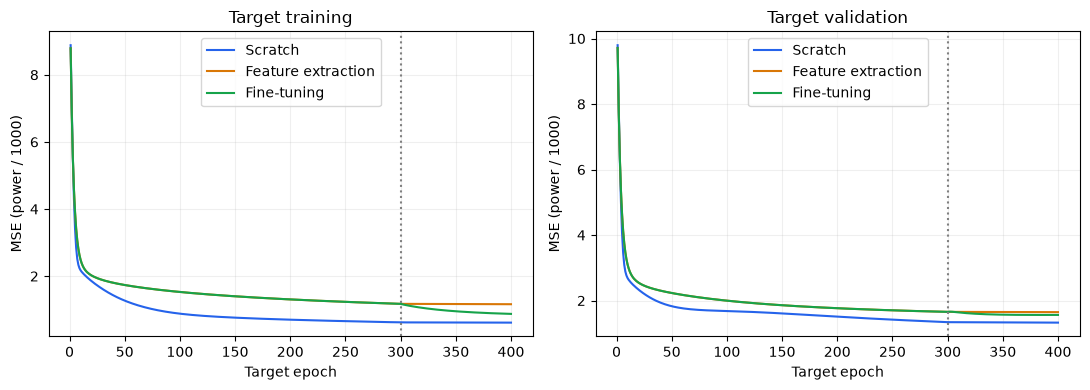

In [5]:
# rows=[]
# for name, model in models.items():
#     train_mse = ...
#     valid_mse = ...
#     rows.append({"strategy":name,"train_mse":train_mse,"valid_mse":valid_mse})
# performance = pd.DataFrame(rows)
# 최저 검증 MSE를 찾고 두 Learning Curve를 그리세요.

rows = []
for name,model in models.items():
    train_mse = float(np.mean((predict_scaled(X_train,model)-y_train)**2))
    valid_mse = float(np.mean((predict_scaled(X_valid,model)-y_valid)**2))
    rows.append({'strategy':name,'train_mse':train_mse,'valid_mse':valid_mse})
performance = pd.DataFrame(rows)
best_strategy = performance.loc[performance['valid_mse'].idxmin(),'strategy']
print(performance.to_string(index=False))
print('최저 검증 MSE 전략:',best_strategy)
fig,axes = plt.subplots(1,2,figsize=(11,4))
colors = {'Scratch':'#2563eb','Feature extraction':'#d97706','Fine-tuning':'#16a34a'}
for name,hist in histories.items():
    axes[0].plot(hist['epoch'],hist['train_mse'],label=name,color=colors[name])
    axes[1].plot(hist['epoch'],hist['valid_mse'],label=name,color=colors[name])
for ax,title in zip(axes,['Target training','Target validation']):
    ax.axvline(300,linestyle=':',color='gray')
    ax.set(xlabel='Target epoch',ylabel='MSE (power / 1000)',title=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
plt.show()


#### 답안 작성 — 결과와 판단 이유를 연결하세요

**Q1. 세 전략의 최종 검증 MSE는 각각 얼마이며 이번 조건에서 무엇이 가장 낮나요?**

- 나의 답변: Scratch: 1.32603345; Feature extraction: 1.64649043; Fine-tuning: 1.56094289이다. 이번 조건의 최저는 Scratch이다.

- 출력값·코드 근거: 400회 최종 결과는 다음과 같다.

| strategy | train_mse | valid_mse |
| --- | --- | --- |
| Scratch | 0.614795899 | 1.32603345 |
| Feature extraction | 1.16356766 | 1.64649043 |
| Fine-tuning | 0.87520023 | 1.56094289 |


- 그렇게 해석한 이유: 전략마다 임의 중간 최저점을 고른 것이 아니라 동일한 400회 종료 모델을 대상 검증 168행에서 평가했다.

**Q2. Feature extraction과 Fine-tuning의 그래프가 처음 300회까지 겹치는 이유는 무엇인가요? 미세조정 이후에는 검증 결과가 어떻게 달라지나요?**

- 나의 답변: 처음 300회는 같은 파라미터·자료·업데이트를 사용해 겹친다. 마지막 100회에는 FT의 은닉층을 풀어 두 경로가 달라지며 검증 결과도 달라진다.

- 출력값·코드 근거: 300회 검증 MSE는 두 전략 모두 1.65443823이다. 400회 FE=1.64649043, FT=1.56094289이다.

- 그렇게 해석한 이유: 두 헤드가 아닌 같은 구조의 모델에 대한 서로 다른 업데이트 전략 비교이다. 동결 해제에 따른 표현 변화가 반드시 검증 향상으로 이어지는 것은 아니다.

**Q3. 이번 결과에서 Scratch가 더 좋으면 전이학습은 쓸모없다고 결론 내릴 수 있나요? 반대로 전이학습이 항상 더 좋아야 하나요?**

- 나의 답변: 결론 낼 수 없다. 한 건물·기간·모델·초기값·설정의 결과일 뿐이다. 사전학습 분포가 대상과 맞지 않으면 전이가 불리할 수 있고, 전이학습이 항상 Scratch보다 좋아야 하는 것도 아니다.

- 출력값·코드 근거: 이번 낮은 MSE 순서는 Scratch → Fine-tuning → Feature extraction이다. 이 순위는 현재 실험 범위의 관측 결과이다.

- 그렇게 해석한 이유: Source와 Target의 관련성·표본 수·미세조정 범위·학습률 등에 따라 유리한 전략이 달라질 수 있다. 전이학습 전체의 유용성을 한 실험으로 부정하거나 보장하지 않는다.

**Q4. MSE의 단위와 비교 범위를 설명하세요. 이것은 독립된 최종 테스트 성능인가요?**

- 나의 답변: 전력소비량을 1000으로 나눈 목표에서 계산한 평균 제곱 오차이다. 현재 5번 건물의 검증 기간에 대한 비교이며 독립 최종 테스트 성능은 아니다.

- 출력값·코드 근거: MSE=mean((예측 kWh/1000−실제 kWh/1000)²)이다. kWh² 척도로 되돌리려면 1000²을 곱하고 RMSE(kWh)는 1000×sqrt(MSE)이다.

- 그렇게 해석한 이유: 단순 평균 kWh 오차나 정확도 %로 읽을 수 없다. 같은 검증 결과를 전략 선택에도 사용하므로 별도 테스트 평가와 구별한다.


### 문제 2-2. 학습 효율과 사전학습 비용 비교

#### 문제 설명

‘학습할 숫자가 적다’, ‘대상에 적응시키는 시간이 짧다’, ‘처음부터 준비한 총비용이 작다’는 서로 다른 설명입니다. 실제 시간을 재고 사전학습 비용을 따로 표시하세요.

#### 요구사항

1. `timing_runs = benchmark(pretrained,repeats=3)`으로 시간을 측정하세요.
2. `stage`별 실행 시간의 **중앙값**을 구하세요. 중앙값은 세 값을 작은 순서로 놓았을 때 가운데 값입니다.
3. 다음 열을 가진 `efficiency` 표를 만드세요.
   - `strategy`: 전략 이름
   - `updated_first_300`, `updated_last_100`: 구간별 업데이트 파라미터 개수
   - `target_seconds`: 대상 학습 400회의 시간 중앙값
   - `source_seconds`: Scratch는 0, 두 전이 전략은 Source 사전학습 시간 중앙값
   - `estimated_total_seconds`: 위 두 시간의 합
4. 사전학습 비용을 제외한 경우와 포함한 경우를 비교하세요.

#### 작성 도움말

```python
median_times = timing_runs.groupby("stage")["seconds"].median()
```

`median_times["Source pretraining"]`으로 사전학습 시간을 읽습니다. 이 표는 **각 전략을 하나 선택해 수행할 때**의 비용입니다. 두 전이 전략을 함께 실험하면 사전학습 모델을 공유할 수 있으므로 전체 실험 비용에 사전학습을 두 번 더할 필요는 없습니다.

반복 측정은 초기값을 고정한 채 시간의 흔들림을 줄이려는 것입니다. 서로 다른 초기값의 성능 안정성을 확인하는 실험은 아닙니다. 실행 시간 순위는 환경에 따라 달라질 수 있습니다.

#### 해석 질문

**Q1.** 각 전략에서 구간별로 몇 개를 업데이트하나요? Feature extraction의 완성 모델도 전체 파라미터가 9개뿐인가요?

**Q2.** 이번 실행에서 대상 학습 시간과 사전학습 포함 추정 시간이 각각 가장 짧은 전략은 무엇인가요? 실제 출력값을 근거로 답하세요.

**Q3.** 고정된 은닉 특징 H를 저장해 재사용할 수 있는 경우와 그럴 수 없는 경우는 무엇인가요? 업데이트 개수 9 대 65가 실행 시간의 정확한 비율인가요?

**Q4.** 이번 추정 총시간에는 무엇이 포함되고 무엇이 빠졌나요? 3회 측정만으로 다른 컴퓨터에서도 같은 속도 차이를 보장할 수 있나요?

#### 제출 결과

반복 측정값, 중앙값, 효율 비교 표, Q1~Q4 답변.


In [6]:
# timing_runs = benchmark(pretrained,repeats=3)
# median_times = timing_runs.groupby("stage")["seconds"].median()
# counts = {"Scratch":(65,65), "Feature extraction":(9,9), "Fine-tuning":(9,65)}
# Source 시간 포함 여부를 구분해 efficiency 표를 만드세요.

timing_runs = benchmark(pretrained,repeats=3)
median_times = timing_runs.groupby('stage')['seconds'].median()
counts = {'Scratch':(65,65),'Feature extraction':(9,9),'Fine-tuning':(9,65)}
efficiency_rows = []
for name in strategies:
    target_time = float(median_times[name])
    source_time = 0.0 if name == 'Scratch' else float(median_times['Source pretraining'])
    efficiency_rows.append({'strategy':name,'updated_first_300':counts[name][0],
        'updated_last_100':counts[name][1],'target_seconds':target_time,
        'source_seconds':source_time,'estimated_total_seconds':target_time+source_time})
efficiency = pd.DataFrame(efficiency_rows)
print('3회 반복 측정')
print(timing_runs.to_string(index=False))
print('단계별 시간 중앙값(초):')
print(median_times.to_string())
print(efficiency.to_string(index=False))


3회 반복 측정
 repeat              stage  seconds
      1 Source pretraining 0.246763
      1            Scratch 0.021830
      1 Feature extraction 0.005801
      1        Fine-tuning 0.009709
      2 Source pretraining 0.248640
      2 Feature extraction 0.005951
      2        Fine-tuning 0.010452
      2            Scratch 0.022526
      3 Source pretraining 0.247331
      3        Fine-tuning 0.010037
      3            Scratch 0.021725
      3 Feature extraction 0.005822
단계별 시간 중앙값(초):
stage
Feature extraction    0.005822
Fine-tuning           0.010037
Scratch               0.021830
Source pretraining    0.247331
          strategy  updated_first_300  updated_last_100  target_seconds  source_seconds  estimated_total_seconds
           Scratch                 65                65        0.021830        0.000000                 0.021830
Feature extraction                  9                 9        0.005822        0.247331                 0.253153
       Fine-tuning                  9  

#### 답안 작성 — 결과와 판단 이유를 연결하세요

**Q1. 각 전략에서 구간별로 몇 개를 업데이트하나요? Feature extraction의 완성 모델도 전체 파라미터가 9개뿐인가요?**

- 나의 답변: Scratch는 65·65개, Feature extraction은 9·9개, Fine-tuning은 9·65개를 업데이트한다. FE 모델 전체 파라미터는 여전히 65개이다.

- 출력값·코드 근거: W1=6×8=48, b1=8, W2=8, b2=1로 총 65개이며 출력층만 9개이다. 효율 표는 다음과 같다.

| strategy | updated_first_300 | updated_last_100 | target_seconds | source_seconds | estimated_total_seconds |
| --- | --- | --- | --- | --- | --- |
| Scratch | 65 | 65 | 0.0209243 | 0 | 0.0209243 |
| Feature extraction | 9 | 9 | 0.005763 | 0.2340773 | 0.2398403 |
| Fine-tuning | 9 | 65 | 0.0093705 | 0.2340773 | 0.2434478 |


- 그렇게 해석한 이유: 고정한 은닉층도 모델 안에 남아 특징 계산에 쓰인다. 업데이트 대상 수가 줄어도 모델 전체를 9개로 축소한 것은 아니다.

**Q2. 이번 실행에서 대상 학습 시간과 사전학습 포함 추정 시간이 각각 가장 짧은 전략은 무엇인가요? 실제 출력값을 근거로 답하세요.**

- 나의 답변: 전체 전략 중 대상 시간 최단은 Feature extraction(0.005763초), Source 포함 추정 최단은 Scratch(0.0209243초)이다.

- 출력값·코드 근거: 반복 시간과 중앙값은 실제 실행 결과이다.

| repeat | stage | seconds |
| --- | --- | --- |
| 1 | Source pretraining | 0.2359911 |
| 1 | Scratch | 0.0214363 |
| 1 | Feature extraction | 0.0058151 |
| 1 | Fine-tuning | 0.0093705 |
| 2 | Source pretraining | 0.2340773 |
| 2 | Feature extraction | 0.005763 |
| 2 | Fine-tuning | 0.0092743 |
| 2 | Scratch | 0.0208748 |
| 3 | Source pretraining | 0.2339388 |
| 3 | Fine-tuning | 0.0095892 |
| 3 | Scratch | 0.0209243 |
| 3 | Feature extraction | 0.0054841 |
중앙값(초): {'Feature extraction': 0.005762999997386942, 'Fine-tuning': 0.00937049999993178, 'Scratch': 0.020924300002661766, 'Source pretraining': 0.23407729999962612}

- 그렇게 해석한 이유: 대상 적응 시간과 처음부터 준비하는 비용은 서로 다른 열이다. 여기서는 성능 조건 없이 전체 전략 시간만 비교했고 과제 B·C에서는 먼저 성능 조건을 적용한다.

**Q3. 고정된 은닉 특징 H를 저장해 재사용할 수 있는 경우와 그럴 수 없는 경우는 무엇인가요? 업데이트 개수 9 대 65가 실행 시간의 정확한 비율인가요?**

- 나의 답변: 입력·은닉층 파라미터와 동작이 고정이면 H를 저장해 재사용할 수 있다. FT 마지막 구간이나 Scratch는 W1·b1이 변하므로 H를 다시 계산한다. 9:65는 업데이트 수 비율이지 시간의 정확한 비율이 아니다.

- 출력값·코드 근거: fit_segment에서 freeze=True일 때 fixed_H·fixed_check를 한 번 계산한다. freeze=False는 매번 hidden_features를 호출한다.

- 그렇게 해석한 이유: 순전파·기울기·손실 기록·배열 처리·호출 비용이 모두 실행 시간에 영향을 준다. 이 모델에는 Dropout·BN 같은 상태 변화 층은 없다.

**Q4. 이번 추정 총시간에는 무엇이 포함되고 무엇이 빠졌나요? 3회 측정만으로 다른 컴퓨터에서도 같은 속도 차이를 보장할 수 있나요?**

- 나의 답변: 측정 함수의 대상 학습·기록 시간과 Source 사전학습 시간의 중앙값을 합친 추정치이다. CSV 읽기·연결·전처리·그래프·설정 탐색·외부 모델 다운로드 등은 포함하지 않는다. 세 번만으로 다른 컴퓨터의 같은 시간 순위를 보장하지 못한다.

- 출력값·코드 근거: 타이머는 pretrain_source·run_strategy 내부에서 작동한다. 소스·대상 중앙값을 더한 값이며 전체 실행의 직접 중앙값과 같을 필요는 없다.

- 그렇게 해석한 이유: 순서를 회전하고 3회 중앙값을 쓰면 흔들림을 줄일 수 있지만 하드웨어·부하·라이브러리 영향을 제거하지는 못한다. 두 전이 전략을 함께 시험하면 Source 모델을 공유하므로 준비 비용을 두 번 더하지 않는다.


---

## 기초 과제. 성능과 비용 조건에 맞춰 선택하기


### 문제 3-1. 상황이 달라지면 선택도 달라질까요?

#### 문제 설명

새로운 모델을 만들지 않고 실습 결과를 활용합니다. 아래 세 상황에서 어떤 전략을 선택할지 근거를 적으세요.

| 상황 | 선택 기준 |
|---|---|
| A | 비용보다 검증 MSE가 가장 낮은 전략을 우선 |
| B | 사전학습 모델이 이미 있음. 검증 MSE가 1.60 이하인 전략 중 대상 학습 시간이 가장 짧은 것 |
| C | 사전학습 모델이 없음. 이번 건물에 한 번만 적용. 검증 MSE가 1.60 이하인 전략 중 Source 포함 추정 시간이 가장 짧은 것 |

**1.60은 선택 연습용 임의 기준**이며 실제 전력 운영에서 정한 허용 오차가 아닙니다. 이번 실습의 `전력소비량/1,000` 단위 MSE에만 적용합니다.

#### 요구사항

1. `performance`와 `efficiency`를 `strategy` 열로 연결하여 `comparison`을 만드세요.
2. `valid_mse <= 1.60`을 만족하는 행을 고르세요.
3. A·B·C의 선택 결과와 근거 수치를 출력하세요.
4. 아래 질문에 각각 2~3문장으로 답하세요.

#### 작성 도움말

`performance.merge(efficiency,on="strategy",validate="one_to_one")`로 표를 연결합니다. `eligible = comparison[comparison["valid_mse"] <= 1.60]`으로 조건을 고릅니다. 최소값 행은 `.loc[열.idxmin()]`으로 찾을 수 있습니다.

#### 해석 질문

**Q1.** 상황 A의 선택과 이유는 무엇인가요?

**Q2.** 상황 B의 선택과 이유는 무엇인가요? 가장 빠른 전략이라고 해서 성능 기준을 무시해도 되나요?

**Q3.** 상황 C에서는 무엇을 선택하나요? B와 선택이 달라질 수 있는 이유와 이번 비교의 한계를 설명하세요.

#### 제출 결과

통합 비교 표, 조건을 통과한 전략, A·B·C의 선택과 Q1~Q3 답변.


In [7]:
# comparison = performance.merge(efficiency,on="strategy",validate="one_to_one")
# eligible = comparison[comparison["valid_mse"] <= 1.60]
# choice_a = ...
# choice_b = ...
# choice_c = ...
# 각 선택의 MSE와 시간 근거를 출력하세요.

comparison = performance.merge(efficiency,on='strategy',validate='one_to_one')
eligible = comparison[comparison['valid_mse'] <= 1.60]
choice_a = comparison.loc[comparison['valid_mse'].idxmin()]
choice_b = eligible.loc[eligible['target_seconds'].idxmin()]
choice_c = eligible.loc[eligible['estimated_total_seconds'].idxmin()]
print('통합 비교:')
print(comparison.to_string(index=False))
print('성능 기준 통과 전략:',eligible['strategy'].tolist())
for label,row in [('A',choice_a),('B',choice_b),('C',choice_c)]:
    print(label,row.to_dict())


통합 비교:
          strategy  train_mse  valid_mse  updated_first_300  updated_last_100  target_seconds  source_seconds  estimated_total_seconds
           Scratch   0.614796   1.326033                 65                65        0.021830        0.000000                 0.021830
Feature extraction   1.163568   1.646490                  9                 9        0.005822        0.247331                 0.253153
       Fine-tuning   0.875200   1.560943                  9                65        0.010037        0.247331                 0.257368
성능 기준 통과 전략: ['Scratch', 'Fine-tuning']
A {'strategy': 'Scratch', 'train_mse': 0.6147958989921096, 'valid_mse': 1.326033445703216, 'updated_first_300': 65, 'updated_last_100': 65, 'target_seconds': 0.021830000001500593, 'source_seconds': 0.0, 'estimated_total_seconds': 0.021830000001500593}
B {'strategy': 'Fine-tuning', 'train_mse': 0.8752002295902293, 'valid_mse': 1.5609428913844032, 'updated_first_300': 9, 'updated_last_100': 65, 'target_seconds':

#### 답안 작성 — 결과와 판단 이유를 연결하세요

**Q1. 상황 A의 선택과 이유는 무엇인가요?**

- 나의 답변: 상황 A는 Scratch를 선택한다. 비용보다 검증 MSE를 우선하는 조건에서 가장 낮은 1.32603345이기 때문이다.

- 출력값·코드 근거: 세 전략 MSE: Scratch: 1.32603345; Feature extraction: 1.64649043; Fine-tuning: 1.56094289. A는 comparison의 valid_mse.idxmin()을 사용한다.

- 그렇게 해석한 이유: 단일 검증 구간에서의 선택이며 다른 건물·기간의 일반적 성능 보장이나 독립 테스트 결과는 아니다.

**Q2. 상황 B의 선택과 이유는 무엇인가요? 가장 빠른 전략이라고 해서 성능 기준을 무시해도 되나요?**

- 나의 답변: 상황 B는 Fine-tuning를 선택한다. 검증 MSE 1.56094289≤1.60을 만족하는 전략 중 대상 학습 중앙값 0.0093705초가 가장 짧다. 빠르다는 이유로 성능 기준을 무시하지 않는다.

- 출력값·코드 근거: 성능 기준 통과 전략: Scratch, Fine-tuning. 통합 표는 다음과 같다.

| strategy | train_mse | valid_mse | updated_first_300 | updated_last_100 | target_seconds | source_seconds | estimated_total_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Scratch | 0.614795899 | 1.32603345 | 65 | 65 | 0.0209243 | 0 | 0.0209243 |
| Feature extraction | 1.16356766 | 1.64649043 | 9 | 9 | 0.005763 | 0.2340773 | 0.2398403 |
| Fine-tuning | 0.87520023 | 1.56094289 | 9 | 65 | 0.0093705 | 0.2340773 | 0.2434478 |


- 그렇게 해석한 이유: 사전학습 모델이 이미 있으므로 대상 적응 비용만 비교하지만, 먼저 valid_mse≤1.60으로 걸러야 한다. 불합격 전략은 시간이 더 짧아도 선택 대상이 아니다.

**Q3. 상황 C에서는 무엇을 선택하나요? B와 선택이 달라질 수 있는 이유와 이번 비교의 한계를 설명하세요.**

- 나의 답변: 상황 C는 Scratch를 선택한다. 성능 조건을 통과한 전략 중 Source 포함 추정 시간 0.0209243초가 가장 짧다. 사전학습 모델이 없는 한 번 적용에서는 준비 비용까지 필요해 B와 선택이 달라질 수 있으며 시간·성능 순위는 이번 실행 범위에 한정된다.

- 출력값·코드 근거: C 선택의 검증 MSE=1.32603345, 대상 시간=0.0209243초, Source 시간=0초이다. B는 target_seconds, C는 estimated_total_seconds를 최소화한다.

- 그렇게 해석한 이유: 1.60은 실습용 임의 기준이다. 시간은 환경에 따라 달라지고 세 전략의 한 건물·고정 초기값 비교이므로 선택을 다른 작업에 그대로 일반화하지 않는다.


---

## 실습 마무리

아래 여섯 질문에 자신의 말로 답하세요. 단순한 체크 목록이 아니라 **용어·코드·실제 결과를 연결하는 복습 문제**입니다. 새 모델을 만들거나 심화 실험을 할 필요는 없습니다. 먼저 답을 작성한 뒤 정답 파일의 상세 해설과 비교하세요.

### 마무리 1. 시작값과 비교 조건

Scratch와 두 전이 전략의 은닉층·출력층 출발점은 어떻게 다른가요? 같은 조건 세 가지 이상과 전이 전략이 추가로 사용하는 자원을 적으세요.

- 나의 답변: Scratch 은닉층은 무작위 초기값, 두 전이 전략은 Source 사전학습 은닉층이다. 출력층은 세 전략 모두 동일한 새 초기값이다. 대상 자료·고정 전처리·구조·총 횟수·구간별 학습률을 같게 하고 Transfer만 Source 학습 자원을 추가 사용한다.

- 코드·수치 근거: W2·b2 동일=True, W1·b1 동일=False. Source 학습 MSE 2.43990183 → 0.390547599 (600회).

- 헷갈렸던 점과 고친 설명: Scratch가 Source 정규화 통계를 쓰는 공정성 문제를 피하려고 이번 강의는 데이터에서 통계를 학습하지 않는 고정 배율 변환을 공통 사용한다.


### 마무리 2. 두 구간의 학습

세 전략의 처음 300회·마지막 100회 업데이트 범위를 쓰고, 두 전이 전략의 300회 모델이 같은 이유를 설명하세요. freeze=True의 뜻도 적으세요.

- 나의 답변: Scratch는 전체 65→65, FE는 head 9→9, FT는 head 9→전체 65개를 학습한다. 두 전이 전략은 처음 300회 계산이 같아 중간 모델이 같다. freeze=True는 은닉층을 고정한다.

- 코드·수치 근거: 300회 모델 동일=True. 마지막 100회 파라미터 변화는 FE의 W1·b1=0, FT의 W1·b1>0이다.

- 헷갈렸던 점과 고친 설명: freeze=True는 전체 학습 중단이 아니다. 6장1강 train_backbone=False와 같은 동결 방향이며 출력층 업데이트는 계속된다.


### 마무리 3. 특징과 모델 크기

Feature extraction은 왜 H를 저장해 재사용할 수 있나요? Fine-tuning의 마지막 구간에서는 왜 다시 계산하나요? 전체 파라미터 수와 업데이트 대상 수, 실행 시간 비율을 구분해 설명하세요.

- 나의 답변: FE는 은닉층과 입력이 고정되어 H를 저장해 재사용한다. FT 마지막 구간은 은닉층이 변해 매번 다시 계산한다. 전체 모델 65개와 head 업데이트 9개, 시간의 실제 비율은 서로 다르다.

- 코드·수치 근거: H는 (168,8), W1·b1 56개와 W2·b2 9개로 총 65개이다. 현재 측정 대상 중앙값은 {'Scratch': 0.020924300002661766, 'Feature extraction': 0.005762999997386942, 'Fine-tuning': 0.00937049999993178}이다.

- 헷갈렸던 점과 고친 설명: 9개만 업데이트해도 고정된 56개 파라미터는 모델 안에 남아 있다. 9/65를 실행 시간의 정확한 비율로 해석하지 않는다.


### 마무리 4. 성능 결과 읽기

세 전략의 최종 검증 MSE 순위를 쓰고, MSE의 계산 척도와 평가 자료를 설명하세요. 이번 결과로 전이학습 전체의 우열이나 독립된 테스트 성능을 말할 수 있나요?

- 나의 답변: 낮은 최종 검증 MSE 순서: Scratch → Fine-tuning → Feature extraction. 목표는 전력소비량/1000이며 대상 검증 168행에서 평가했다. 전이학습 전체의 우열이나 독립 테스트 성능을 말할 수 없다.

- 코드·수치 근거: Scratch: 1.32603345; Feature extraction: 1.64649043; Fine-tuning: 1.56094289. 모두 400회 종료 모델을 비교했다.

- 헷갈렸던 점과 고친 설명: 각 전략의 중간 최저점을 임의 선택하지 않았다. 같은 척도 안의 검증 비교이며 6장1강 표준화 MSE와 숫자를 그대로 비교하지 않는다.


### 마무리 5. 학습 효율 읽기

target_seconds·source_seconds·estimated_total_seconds의 차이를 설명하세요. 3회 중앙값의 뜻, 포함하지 않은 작업, 사전학습 모델을 공유할 때의 비용 해석도 적으세요.

- 나의 답변: target_seconds는 대상 400회 중앙값, source_seconds는 준비 비용(스크래치는 0), estimated_total_seconds는 둘의 합이다. 3회 중앙값은 세 시간 중 가운데 값이며 모델을 공유하면 Source 비용은 한 번만 필요하다.

- 코드·수치 근거: 실제 효율 표는 다음과 같다.

| strategy | updated_first_300 | updated_last_100 | target_seconds | source_seconds | estimated_total_seconds |
| --- | --- | --- | --- | --- | --- |
| Scratch | 65 | 65 | 0.0209243 | 0 | 0.0209243 |
| Feature extraction | 9 | 9 | 0.005763 | 0.2340773 | 0.2398403 |
| Fine-tuning | 9 | 65 | 0.0093705 | 0.2340773 | 0.2434478 |


- 헷갈렸던 점과 고친 설명: CSV 읽기·전처리·시각화 등은 타이머 밖이다. 반복 측정은 시간 흔들림 완화이며 서로 다른 모델 초기값의 성능 안정성을 시험한 것이 아니다.


### 마무리 6. 상황별 선택

검증 MSE 1.60 조건을 통과한 전략을 고르고, 과제 A·B·C에서 어떤 열을 최소화하는지와 이번 선택 결과를 설명하세요. 가장 빠른 전략이 조건을 통과하지 못하면 어떻게 하나요?

- 나의 답변: 성능 조건 통과: Scratch, Fine-tuning. A는 valid_mse, B는 조건 통과 후 target_seconds, C는 조건 통과 후 estimated_total_seconds를 최소화한다. 이번 선택은 A=Scratch, B=Fine-tuning, C=Scratch이다.

- 코드·수치 근거: 통합 비교 표는 다음과 같다.

| strategy | train_mse | valid_mse | updated_first_300 | updated_last_100 | target_seconds | source_seconds | estimated_total_seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Scratch | 0.614795899 | 1.32603345 | 65 | 65 | 0.0209243 | 0 | 0.0209243 |
| Feature extraction | 1.16356766 | 1.64649043 | 9 | 9 | 0.005763 | 0.2340773 | 0.2398403 |
| Fine-tuning | 0.87520023 | 1.56094289 | 9 | 65 | 0.0093705 | 0.2340773 | 0.2434478 |


- 헷갈렸던 점과 고친 설명: 가장 빠른 전략이 valid_mse≤1.60을 만족하지 못하면 제외한다. 조건 통과 전략이 전혀 없다면 임의로 하나를 고르기보다 기준·모델·설정 재검토가 필요하다.


## 제출 전 확인

- 실습 2개와 기초 과제 1개의 출력, 해석 질문 17개에 모두 답했나요?
- 실습 마무리 여섯 문항에 설명과 근거를 적었나요?
- 앞 강의와 다른 전처리, freeze의 True·False 의미를 구분했나요?
- 300회 중간 모델과 400회 최종 모델, 9개 업데이트와 65개 전체 파라미터를 구분했나요?
- 검증 성능·대상 시간·Source 포함 추정 시간을 각각 올바른 열에서 읽었나요?
- B·C에서는 성능 조건을 먼저 적용한 뒤 시간을 비교했나요?
- 시간에 관한 답변은 현재 자신의 실행 결과를 기준으로 썼나요?

정답 파일의 표와 그래프는 제공된 전기사용량·building_info 데이터로 실제 실행한 결과입니다. 손실은 같은 설정에서 재현될 수 있지만 마지막 소수점과 실행 시간은 환경에 따라 달라질 수 있습니다. 시간 수치·전략 이름 암기보다 조건에 맞는 해석이 중요합니다.
